# Where in chemical space each strategy searched

t-SNE of the MACCS fingerprints of the whole recombined library, with the molecules each
strategy actually selected highlighted.

One run per strategy, all from the same seed so they share a starting set, taken from
`Results/init100_clustered_parents_10seeds` (clustered parent selection, 100 starting
molecules, 20 cycles).

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from rdkit import RDLogger

import analysis_utils as an
import docking_utils
import utils

RDLogger.DisableLog("rdApp.*")

In [2]:
HERE = Path(_dh[-1])
RESULTS_FOLDER = HERE / ".." / "Results" / "all_seeds_2026-10-28-16-00"
FIGURE_FOLDER = RESULTS_FOLDER
AFFINITY_FILE = HERE / ".." / "data" / "recombination_library" / "predictions_skip_hyde_random_split_large.csv"
LIBRARY_SDF = HERE / ".." / "data" / "recombination_library" / "final_recombined_library_skip_hyde_large.sdf"

TOP_NUMS = [50, 100, 500]
STRATEGIES = ["greedy", "diverse", "random"]
COLORS = {"greedy": "C0", "diverse": "C1", "random": "grey"}
# bigger points for the two active strategies, which select far fewer molecules
SIZES = {"greedy": 26, "diverse": 26, "random": 8}

## Pick one seed, used for every strategy

All three strategies share a starting set for a given seed, so using the same seed keeps
the comparison fair. The seed chosen is the one where the two active strategies together
recovered the most of the overall top 100; set `SEED` by hand to look at another.

In [3]:
sorted_affs = an.sort_affinities(docking_utils.read_affinities(str(AFFINITY_FILE)))
top_sets = {k: {frag for frag, _ in sorted_affs[:k]} for k in TOP_NUMS}


def load_runs(folder):
    """{strategy: {seed: DataFrame}} for every result file in the folder."""
    runs = {}
    for path in sorted(Path(folder).glob("*.csv")):
        parts = path.stem.split("_")
        # skip anything that is not a result file, e.g. a table saved beside them
        if "kinodata" not in parts or not any(p.startswith("seed") for p in parts):
            continue
        strategy = parts[parts.index("kinodata") + 1]
        seed = int(next(p for p in parts if p.startswith("seed"))[4:])
        runs.setdefault(strategy, {})[seed] = pd.read_csv(path)
    return runs


runs = load_runs(RESULTS_FOLDER)

recovered = pd.DataFrame({
    strategy: {seed: len(set(df.frag_ids) & top_sets[100]) for seed, df in by_seed.items()}
    for strategy, by_seed in runs.items()
})
recovered["active total"] = recovered[["greedy", "diverse"]].sum(axis=1)
print("top 100 ligands recovered per seed:")
print(recovered.sort_values("active total", ascending=False).to_string())

SEED = int(recovered["active total"].idxmax())   # change this to use another seed
print(f"\nusing seed {SEED} for every strategy\n")

best_runs = {strategy: (SEED, by_seed[SEED]) for strategy, by_seed in runs.items()}
for strategy in STRATEGIES:
    seed, df = best_runs[strategy]
    found = set(df.frag_ids)
    print(f"{strategy:<9} seed {seed}: {len(df)} molecules, "
          + ", ".join(f"top {k}: {len(found & top_sets[k])}" for k in TOP_NUMS))

top 100 ligands recovered per seed:
   diverse  greedy  random  active total
8       32      53       4            85
9       43      36       2            79
6       25      49       0            74
2       22      50       0            72
5       29      43       2            72
4       32      37       3            69
0       16      48       1            64
7       24      25       2            49
3        4      43       2            47
1       12      33       0            45

using seed 8 for every strategy

greedy    seed 8: 858 molecules, top 50: 28, top 100: 53, top 500: 163
diverse   seed 8: 499 molecules, top 50: 18, top 100: 32, top 500: 103
random    seed 8: 824 molecules, top 50: 1, top 100: 4, top 500: 9


## The library and what each run selected

In [4]:
all_mols = utils.read_sdf(str(LIBRARY_SDF))
all_mols_df = pd.DataFrame({
    "ROMol": all_mols,
    "frag_ids": [utils.sort_ligand_name("_".join(mol.GetProp("_Name").split("_")[:-1]))
                 for mol in all_mols],
})
print(f"{len(all_mols_df)} molecules in the library")

75902 molecules in the library


In [5]:
# one column per strategy, and one per top k, using set membership rather than row loops
for strategy in STRATEGIES:
    seed, df = best_runs[strategy]
    all_mols_df[strategy] = all_mols_df.frag_ids.isin(set(df.frag_ids)).astype(int)

for k in TOP_NUMS:
    all_mols_df[f"top{k}"] = all_mols_df.frag_ids.isin(top_sets[k]).astype(int)

summary = pd.DataFrame({
    "selected": {s: int(all_mols_df[s].sum()) for s in STRATEGIES},
    "of which in the top 100": {s: int((all_mols_df[s] & all_mols_df["top100"]).sum())
                                for s in STRATEGIES},
})
print(f"molecules of the top k present in the library: "
      + ", ".join(f"top {k}: {int(all_mols_df[f'top{k}'].sum())}" for k in TOP_NUMS))
summary

molecules of the top k present in the library: top 50: 50, top 100: 100, top 500: 500


,selected,of which in the top 100
greedy,788,53
diverse,496,32
random,821,4


## t-SNE of the whole library

Fitted on a random sample and the rest added to that embedding, which keeps a library this
size tractable. This is the slow cell, a few minutes.

In [6]:
import numpy as np
import openTSNE
from rdkit.Chem import MACCSkeys
from sklearn.decomposition import PCA


def create_tsne_embedding(mol_df, sample_size=10000, perplexity=50, n_jobs=1, random_state=0):
    """
    t-SNE embedding of MACCS fingerprints with openTSNE.

    For large sets, t-SNE is fitted on a random sample of `sample_size` molecules
    and the remaining molecules are added to that embedding with `transform`.
    Returns an (n, 2) array in the same row order as `mol_df`.

    Keep n_jobs=1: in this (x86 / Rosetta) environment more threads are slower
    and n_jobs=32 crashes the kernel.
    """
    fps = np.array([list(MACCSkeys.GenMACCSKeys(mol)) for mol in mol_df.ROMol], dtype=np.uint8)
    print("FP done")
    crds = PCA(n_components=50, random_state=random_state).fit_transform(fps)
    print("PCA done")

    n = len(crds)
    rng = np.random.default_rng(random_state)
    sample_idx = np.sort(rng.choice(n, size=min(sample_size, n), replace=False))
    rest_idx = np.setdiff1d(np.arange(n), sample_idx)

    # perplexity must be clearly smaller than the number of points
    perplexity = min(perplexity, (len(sample_idx) - 1) / 3)
    affinities = openTSNE.affinity.PerplexityBasedNN(
        crds[sample_idx], perplexity=perplexity, n_jobs=n_jobs, random_state=random_state
    )
    print(f"affinities done ({len(sample_idx)} molecules)")
    init = openTSNE.initialization.rescale(crds[sample_idx, :2])
    embedding = openTSNE.TSNE(n_jobs=n_jobs, random_state=random_state, verbose=True).fit(
        affinities=affinities, initialization=init
    )
    print("TSNE done")

    crds_embedded = np.zeros((n, 2))
    crds_embedded[sample_idx] = embedding
    if len(rest_idx) > 0:
        crds_embedded[rest_idx] = embedding.transform(crds[rest_idx])
        print(f"added remaining {len(rest_idx)} molecules")
    return crds_embedded

In [7]:
crds_embedded = create_tsne_embedding(all_mols_df)
tsne_df = pd.DataFrame(crds_embedded, columns=["X", "Y"])
for column in STRATEGIES + [f"top{k}" for k in TOP_NUMS]:
    tsne_df[column] = all_mols_df[column].to_numpy()
tsne_df.shape

FP done
PCA done
affinities done (10000 molecules)
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=833.33 for 250 iterations...
Iteration   50, KL divergence 4.5745, 50 iterations in 1.0173 sec
Iteration  100, KL divergence 4.6057, 50 iterations in 0.9592 sec
Iteration  150, KL divergence 4.6054, 50 iterations in 0.9799 sec
Iteration  200, KL divergence 4.6053, 50 iterations in 0.9744 sec
Iteration  250, KL divergence 4.6054, 50 iterations in 0.9767 sec
   --> Time elapsed: 4.91 seconds
===> Running optimization with exaggeration=1.00, lr=10000.00 for 500 iterations...
Iteration   50, KL divergence 1.9291, 50 iterations in 1.0674 sec
Iteration  100, KL divergence 1.7554, 50 iterations in 1.5878 sec
Iteration  150, KL divergence 1.6802, 50 iterations in 2.3366 sec


(75902, 8)

## Explored space

Every molecule in the library in grey, the ones each run selected in colour.

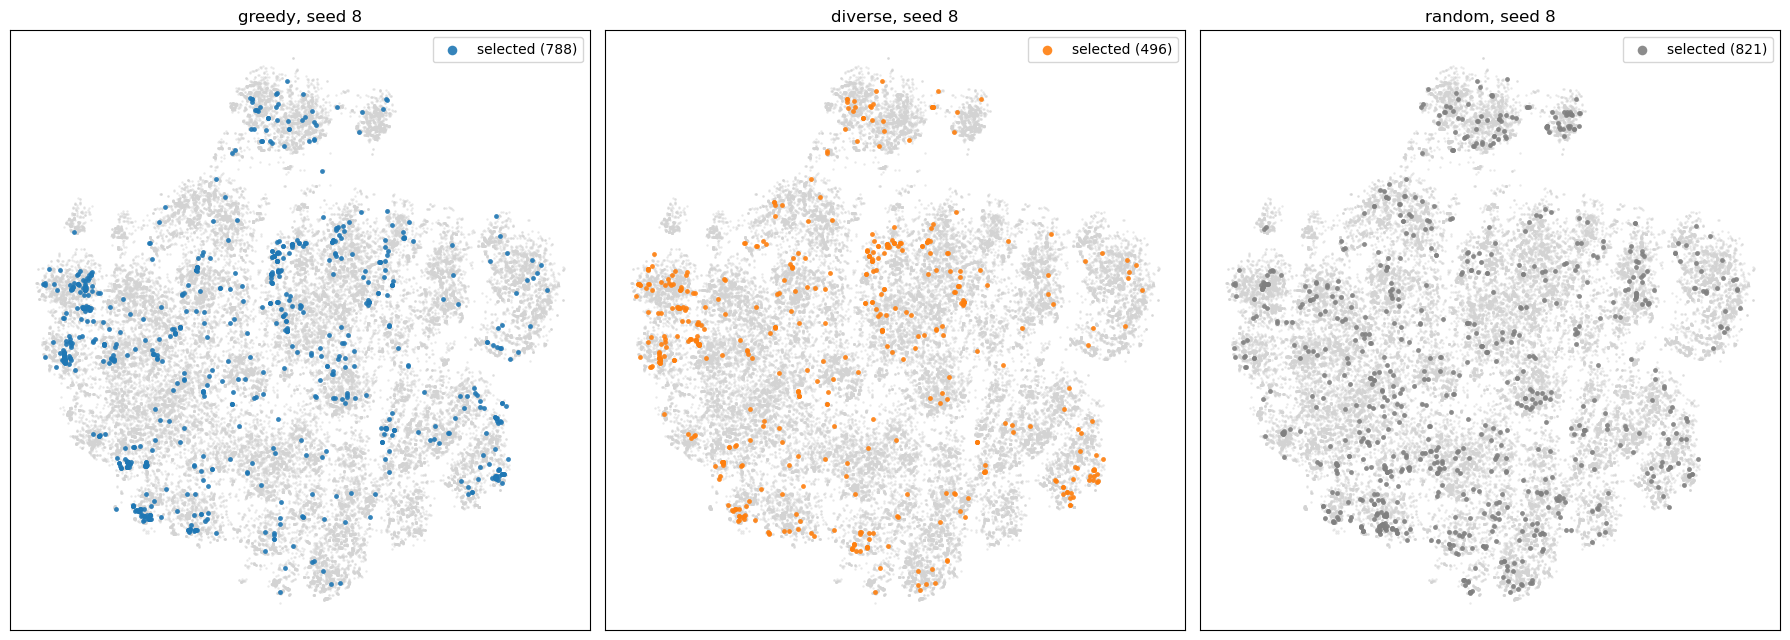

In [8]:
fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(18, 6.5), sharex=True, sharey=True)

for ax, strategy in zip(axes, STRATEGIES):
    seed, df = best_runs[strategy]
    rest = tsne_df[tsne_df[strategy] == 0]
    picked = tsne_df[tsne_df[strategy] == 1]
    ax.scatter(rest.X, rest.Y, s=3, c="lightgrey", alpha=0.5, linewidths=0)
    ax.scatter(picked.X, picked.Y, s=12, c=COLORS[strategy], alpha=0.9, linewidths=0,
               label=f"selected ({len(picked)})")
    ax.set_title(f"{strategy}, seed {seed}")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="upper right", markerscale=2)

plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "chemical_space_explored_best_seed.svg", format="svg",
            bbox_inches="tight")
plt.show()

## Where the best ligands are, and which of them each run found

Grey is the rest of the library, light red the top k ligands the run missed, colour the
ones it found.

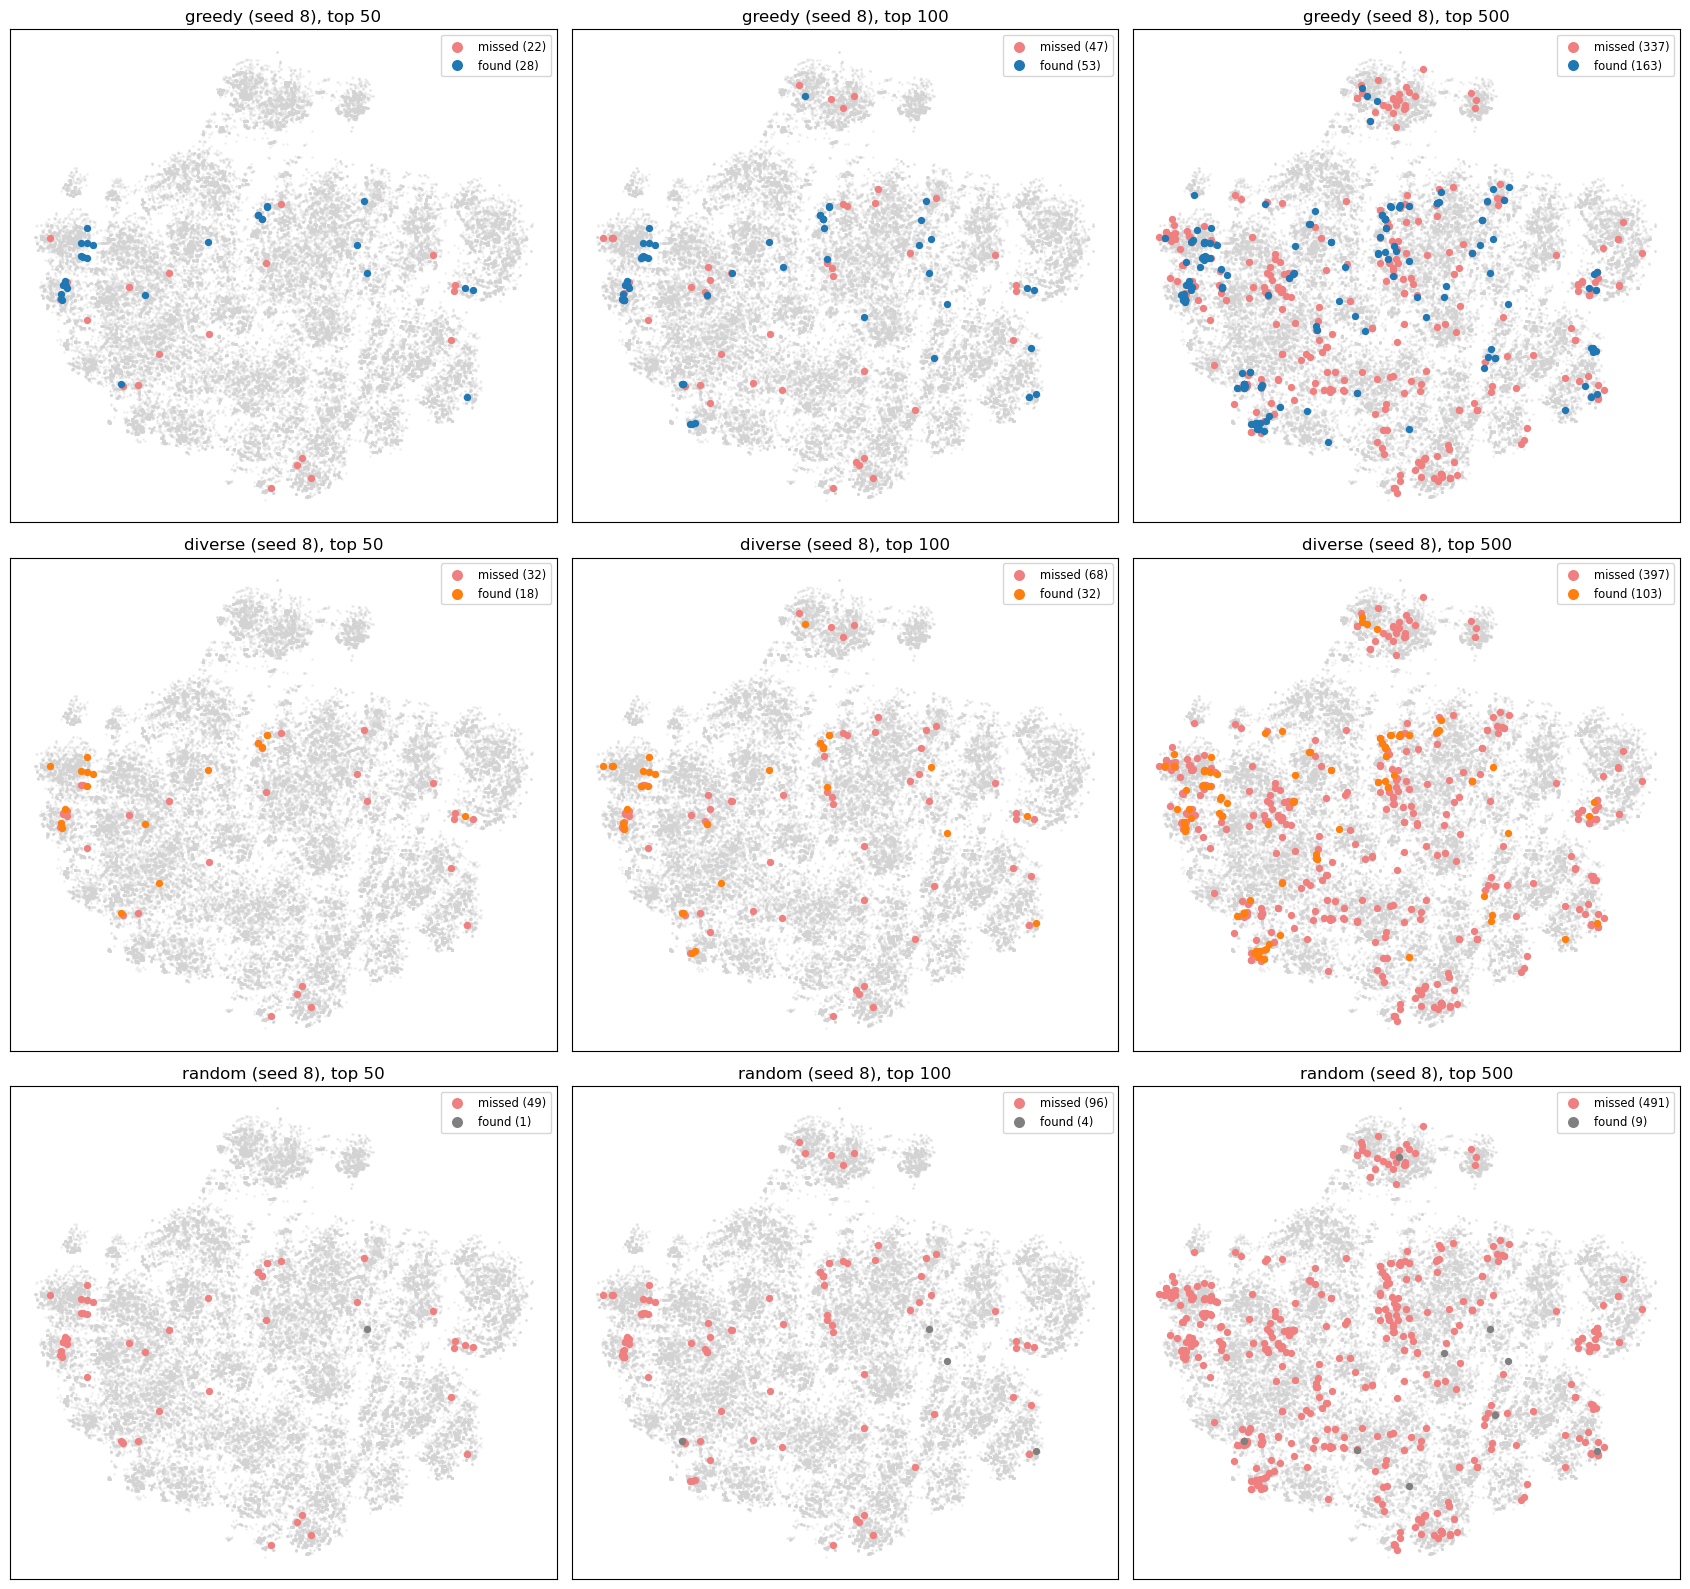

In [9]:
fig, axes = plt.subplots(len(STRATEGIES), len(TOP_NUMS),
                         figsize=(17, 16), sharex=True, sharey=True)

for row, strategy in enumerate(STRATEGIES):
    seed, _ = best_runs[strategy]
    for col, k in enumerate(TOP_NUMS):
        ax = axes[row][col]
        column = f"top{k}"
        rest = tsne_df[tsne_df[column] == 0]
        missed = tsne_df[(tsne_df[column] == 1) & (tsne_df[strategy] == 0)]
        found = tsne_df[(tsne_df[column] == 1) & (tsne_df[strategy] == 1)]
        ax.scatter(rest.X, rest.Y, s=3, c="lightgrey", alpha=0.4, linewidths=0)
        ax.scatter(missed.X, missed.Y, s=28, c="lightcoral", alpha=1, linewidths=0,
                   label=f"missed ({len(missed)})")
        ax.scatter(found.X, found.Y, s=28, c=COLORS[strategy], alpha=1, linewidths=0,
                   label=f"found ({len(found)})")
        ax.set_title(f"{strategy} (seed {seed}), top {k}")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.legend(loc="upper right", markerscale=1.5, fontsize="small")

plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "chemical_space_top_k_best_seed.svg", format="svg",
            bbox_inches="tight")
plt.show()

## All three runs on one map

Shows how much the regions they search overlap.

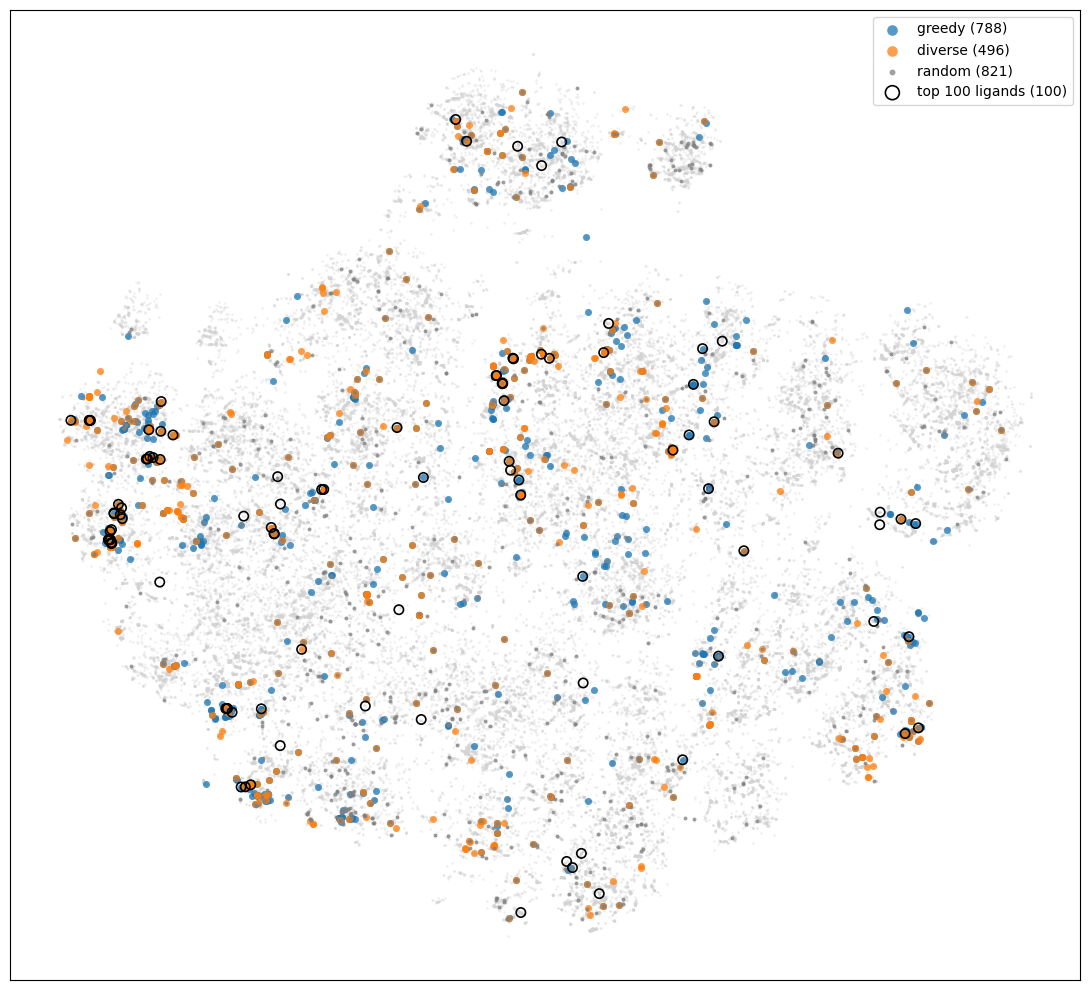

In [10]:
fig, ax = plt.subplots(figsize=(11, 10))
ax.scatter(tsne_df.X, tsne_df.Y, s=3, c="lightgrey", alpha=0.4, linewidths=0)
for strategy in STRATEGIES:
    picked = tsne_df[tsne_df[strategy] == 1]
    ax.scatter(picked.X, picked.Y, s=SIZES[strategy], c=COLORS[strategy], alpha=0.75,
               linewidths=0, label=f"{strategy} ({len(picked)})")
top100 = tsne_df[tsne_df["top100"] == 1]
ax.scatter(top100.X, top100.Y, s=45, facecolors="none", edgecolors="black", linewidths=1.2,
           label=f"top 100 ligands ({len(top100)})")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc="upper right", markerscale=1.5)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "chemical_space_all_strategies.svg", format="svg",
            bbox_inches="tight")
plt.show()